# Análisis exploratorio: influenza aviar en mamíferos

Exploración del dataset limpio `datos/avian_clean.csv`: calidad, evolución temporal, distribución geográfica y por especies, y resultados reportados. Ejecuta las celdas en orden para actualizar tablas y gráficos.

## 1. Carga e inspección general

In [9]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

dataset_candidates = [
    Path("datos/avian_clean.csv"),
    Path("../datos/avian_clean.csv"),
]
dataset_path = next((path for path in dataset_candidates if path.is_file()), None)
if dataset_path is None:
    raise FileNotFoundError(
        f"No se encontró datos/avian_clean.csv desde {Path.cwd()}. "
        "Ejecuta primero codigo/01_limpieza.ipynb."
    )

df = pd.read_csv(dataset_path)
required_columns = {
    "start_date_outbreak", "species_clean", "species_group",
    "country_name", "outcome", "lethal", "total_cases", "total_deaths",
}
missing_columns = required_columns.difference(df.columns)
if missing_columns:
    raise ValueError(
        "Faltan columnas requeridas: " + ", ".join(sorted(missing_columns))
    )

dates = pd.to_datetime(df["start_date_outbreak"], errors="coerce")
print(f"Archivo: {dataset_path.resolve()}")
print(f"Registros: {len(df):,} | Variables: {df.shape[1]}")
print(f"Fechas de inicio válidas: {dates.notna().sum():,} de {len(df):,}")
display(df.head())

Archivo: C:\Users\matta\Desktop\UNIVERSIDAD\2026-2\MDD\mdd-proyecto\datos\avian_clean.csv
Registros: 379 | Variables: 59
Fechas de inicio válidas: 379 de 379


,report_id,report_date,event_id,genotype_serotype_subtype,test_name_1,laboratory_name_1,first_result_date_1,latest_result_date_1,result_1,test_name_2,...,ctl_zoning,ctl_screening,ctl_none,ctl_unknown,ctl_count,lethal,certified,total_cases_missing,total_deaths_missing,log_cases
0,IN_153005,2021-12-17,4185,H5N1,Real-time polymerase chain reaction (real-time...,Estonian Veterinary and Food Laboratory (VFL),44525,44525,Positive,NaN,...,0,0,1,0,0.0,1.0,True,0,0,0.693147
1,FUR_162547,2023-08-30,5037,H5N1,Real-time reverse transcription polymerase cha...,National Reference and OIE/FAO Laboratory for ...,45028,45044,Positive,NaN,...,0,1,0,0,2.0,1.0,True,0,0,0.693147
2,FUR_162547,2023-08-30,5037,H5N1,Real-time reverse transcription polymerase cha...,National Reference and OIE/FAO Laboratory for ...,45028,45044,Positive,NaN,...,0,1,0,0,2.0,1.0,True,0,0,0.693147
3,FUR_162547,2023-08-30,5037,H5N1,Virus neutralisation tests (Ab VNT),National Reference and OIE/FAO Laboratory for ...,45028,45068,Positive,NaN,...,1,0,0,0,6.0,0.0,True,0,1,1.791759
4,FUR_162547,2023-08-30,5037,H5N1,Virus neutralisation tests (Ab VNT),National Reference and OIE/FAO Laboratory for ...,45028,45068,Positive,NaN,...,1,0,0,0,6.0,0.0,True,0,1,0.693147


## 2. Calidad y valores faltantes

El porcentaje de faltantes usa el total de registros como denominador. Las fechas faltantes de cierre pueden corresponder a brotes aún abiertos.

Los mínimos de `total_cases` y `total_deaths` son cero. El dataset por sí solo no permite determinar si esos valores representan ceros confirmados, reportes iniciales incompletos u otra forma de registro; por ello, no se interpretan automáticamente como ausencia real de casos o muertes.

In [10]:
missing = (
    df.isna().sum().rename("faltantes").to_frame()
    .assign(porcentaje=lambda table: table["faltantes"] / len(df) * 100)
    .query("faltantes > 0")
    .sort_values("faltantes", ascending=False)
)
print(f"Duplicados exactos: {df.duplicated().sum():,}")
display(missing.head(12).style.format({"porcentaje": "{:.1f}%"}))
display(df[["total_cases", "total_deaths"]].describe().round(2))

Duplicados exactos: 0


,faltantes,porcentaje
latest_result_date_2,267,70.4%
test_name_2,264,69.7%
laboratory_name_2,264,69.7%
first_result_date_2,264,69.7%
total_killed_and_disposed_of,255,67.3%
result_2,251,66.2%
outbreak_reference,213,56.2%
third_administrative_division,210,55.4%
duration_days,112,29.6%
end_date_outbreak,112,29.6%


,total_cases,total_deaths
count,358.00,287.00
mean,1.75,1.89
std,1.93,2.76
min,0.00,0.00
25%,1.00,1.00
50%,1.00,1.00
75%,2.00,2.00
max,17.00,27.00


## 3. Evolución temporal

Conteo de registros según el mes de inicio del brote. Son frecuencias del dataset, no tasas de incidencia.

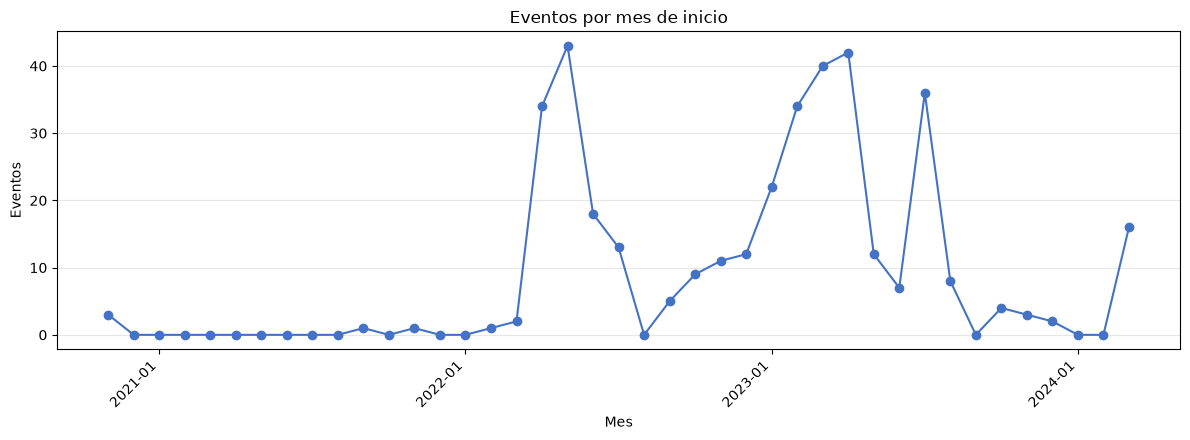

,mes,eventos
18,2022-05,43
29,2023-04,42
28,2023-03,40
32,2023-07,36
17,2022-04,34
27,2023-02,34
26,2023-01,22
19,2022-06,18
40,2024-03,16
20,2022-07,13


In [11]:
monthly_counts = dates.dropna().dt.to_period("M").value_counts().sort_index()
month_index = pd.period_range(monthly_counts.index.min(), monthly_counts.index.max(), freq="M")
monthly = (
    monthly_counts.reindex(month_index, fill_value=0)
    .rename("eventos").rename_axis("mes").reset_index()
)
monthly["mes"] = monthly["mes"].astype(str)
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(monthly["mes"], monthly["eventos"], marker="o", color="#4472C4")
ax.set(title="Eventos por mes de inicio", xlabel="Mes", ylabel="Eventos")
year_ticks = monthly.index[monthly["mes"].str.endswith("-01")]
ax.set_xticks(year_ticks)
ax.set_xticklabels(monthly.loc[year_ticks, "mes"], rotation=45, ha="right")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()
display(monthly.nlargest(10, "eventos").sort_values("eventos", ascending=False))

## 4. Distribución geográfica

La concentración de reportes en ciertos países no implica necesariamente mayor abundancia del virus: también puede reflejar diferencias en vigilancia epidemiológica, capacidad de detección y notificación oficial a la OMSA mediante WAHIS.

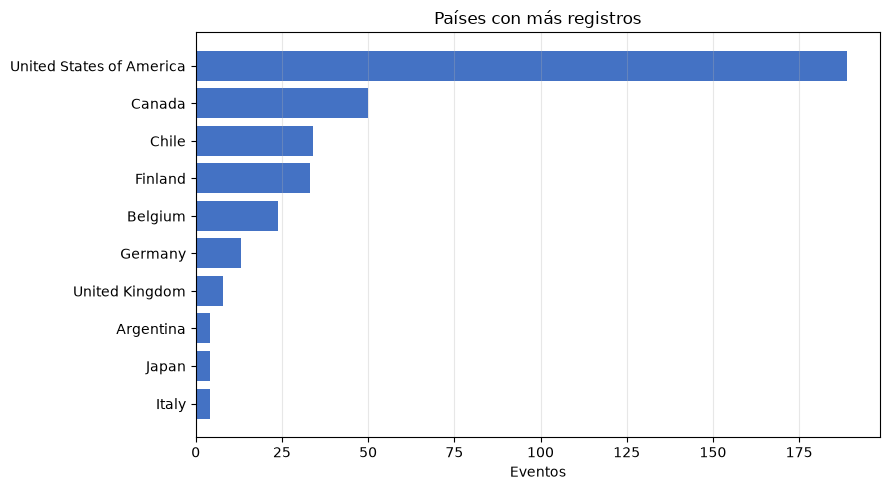

,país,eventos
0,United States of America,189
1,Canada,50
2,Chile,34
3,Finland,33
4,Belgium,24
5,Germany,13
6,United Kingdom,8
7,Italy,4
8,Japan,4
9,Argentina,4


In [12]:
country_counts = df["country_name"].value_counts().rename_axis("país").reset_index(name="eventos")
top_countries = country_counts.head(10).sort_values("eventos")
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(top_countries["país"], top_countries["eventos"], color="#4472C4")
ax.set(title="Países con más registros", xlabel="Eventos", ylabel="")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()
display(country_counts.head(10))

## 5. Especies y grupos

La presencia de cánidos y mustélidos terrestres puede ser compatible con su exposición como depredadores o carroñeros de aves silvestres infectadas; los registros de mamíferos marinos pueden concentrarse en episodios de mortalidad costera, incluidos lobos marinos del Pacífico sur. Estas son hipótesis ecológicas plausibles, no mecanismos demostrados por los conteos del dataset.

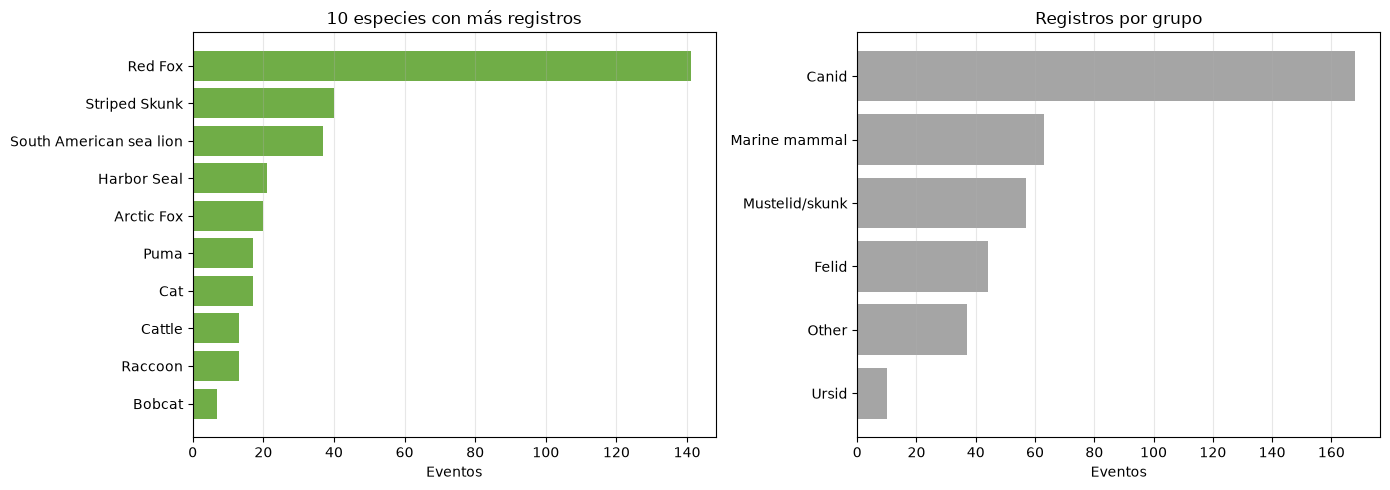

,especie,eventos
0,Red Fox,141
1,Striped Skunk,40
2,South American sea lion,37
3,Harbor Seal,21
4,Arctic Fox,20
5,Cat,17
6,Puma,17
7,Raccoon,13
8,Cattle,13
9,Bobcat,7


,grupo,eventos
0,Ursid,10
1,Other,37
2,Felid,44
3,Mustelid/skunk,57
4,Marine mammal,63
5,Canid,168


In [13]:
species_counts = df["species_clean"].value_counts().rename_axis("especie").reset_index(name="eventos")
group_counts = df["species_group"].value_counts().sort_values()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
top_species = species_counts.head(10).sort_values("eventos")
axes[0].barh(top_species["especie"], top_species["eventos"], color="#70AD47")
axes[0].set(title="10 especies con más registros", xlabel="Eventos", ylabel="")
axes[1].barh(group_counts.index, group_counts.values, color="#A5A5A5")
axes[1].set(title="Registros por grupo", xlabel="Eventos", ylabel="")
for ax in axes:
    ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()
display(species_counts.head(10))
display(group_counts.rename_axis("grupo").reset_index(name="eventos"))

## 6. Resultados reportados y letalidad

La proporción letal se calcula solo con registros cuyo resultado está clasificado (`lethal` no nulo). Se muestra el tamaño de cada grupo para contextualizar porcentajes basados en distintos denominadores.

,resultado,eventos
0,death,329
1,positive,34
2,not certified,16


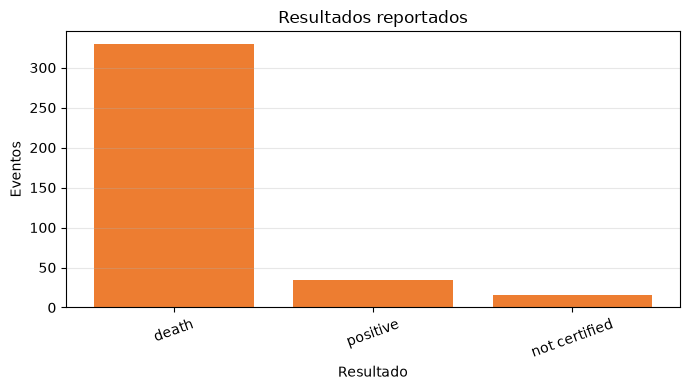

,eventos_clasificados,proporcion_letal
species_group,,
Marine mammal,63,100.0%
Mustelid/skunk,56,94.6%
Ursid,10,90.0%
Canid,167,89.8%
Felid,41,87.8%
Other,26,69.2%


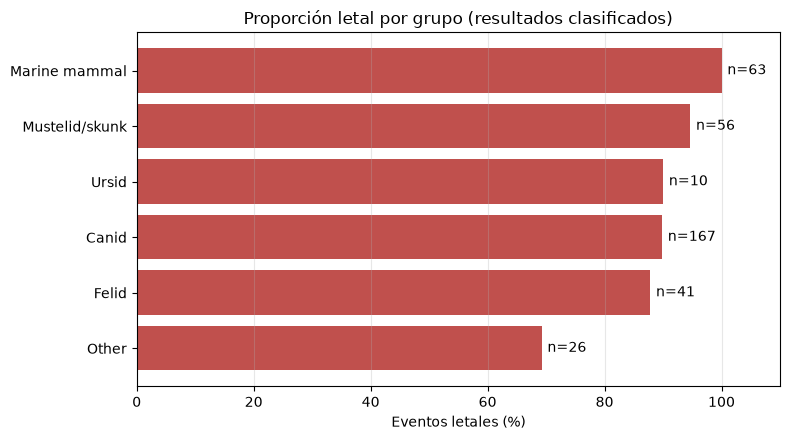

Proporción letal global entre resultados clasificados: 90.6% (363 de 379 registros)


In [14]:
outcome_counts = (
    df["outcome"].fillna("unknown").value_counts()
    .rename_axis("resultado").reset_index(name="eventos")
)
display(outcome_counts)
fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(outcome_counts["resultado"], outcome_counts["eventos"], color="#ED7D31")
ax.set(title="Resultados reportados", xlabel="Resultado", ylabel="Eventos")
ax.tick_params(axis="x", labelrotation=0)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

classified = df.dropna(subset=["lethal"])
lethality = (
    classified.groupby("species_group")["lethal"]
    .agg(eventos_clasificados="count", proporcion_letal="mean")
    .sort_values("proporcion_letal", ascending=False)
)
display(lethality.style.format({"proporcion_letal": "{:.1%}"}))
fig, ax = plt.subplots(figsize=(8, 4.5))
plot_data = lethality.sort_values("proporcion_letal")
bars = ax.barh(plot_data.index, plot_data["proporcion_letal"] * 100, color="#C0504D")
for bar, count in zip(bars, plot_data["eventos_clasificados"]):
    ax.text(bar.get_width() + 1, bar.get_y() + bar.get_height() / 2, f"n={count}", va="center")
ax.set(title="Proporción letal por grupo (resultados clasificados)", xlabel="Eventos letales (%)", ylabel="", xlim=(0, 110))
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()
print(f"Proporción letal global entre resultados clasificados: {classified['lethal'].mean():.1%} ({len(classified)} de {len(df)} registros)")

## Hallazgos principales

- El dataset contiene **379 registros** y **59 variables**, con fechas de inicio entre **2020-11-21 y 2024-03-25**.
- **Estados Unidos** reúne la mayor cantidad de reportes (**189**), seguido de Canadá (**50**) y Chile (**34**).
- **Red Fox** es la especie más registrada (**141**); después aparecen Striped Skunk (**40**) y South American sea lion (**37**).
- Hay **363 resultados clasificados**: **329 letales** y **34 positivos no letales**. La proporción letal entre los clasificados es **90,6%**; los 16 registros restantes no tienen clasificación.
- El desbalance entre resultados clasificados implica que un clasificador que prediga siempre la clase mayoritaria puede superar el 90% de accuracy. En el baseline, acompaña esa métrica con F1 macro, precisión y recall por clase, matriz de confusión y curvas/métricas de precisión-recall. Evita fuga de información: variables como `total_deaths` o `total_killed_and_disposed_of` no deben usarse para predecir `lethal` o `outcome`, porque están directamente relacionadas con la definición del desenlace.
- Hay campos con alta ausencia de datos, especialmente los asociados a una segunda prueba de laboratorio y a animales eliminados/dispuestos. Revisa la tabla de faltantes antes de usar esas variables.

**Interpretación:** estos conteos describen los reportes presentes en el dataset; no son tasas poblacionales de infección o mortalidad y no demuestran causalidad. La distribución geográfica refleja también los sistemas de vigilancia y notificación; la proporción letal está condicionada a que el resultado haya sido clasificado.